# Análise exploratória do CIC-IDS2017

Este notebook examina o conjunto **já limpo** pelo pipeline (`nids data clean`) para responder
perguntas que viram decisões antes do treino dos modelos:

1. As janelas dos ataques fazem sentido depois da correção do relógio de 12 horas?
2. Há atributos redundantes?
3. O que fazer com valores negativos e fluxos de duração zero?
4. O que a janela TCP `-1` e o protocolo revelam?
5. Quanto a porta de destino sozinha já separa os ataques?
6. Como são as distribuições dos atributos?
7. O tráfego normal muda entre os dias?
8. Como ficam as classes raras nos protocolos de divisão?

As propostas de decisão estão resumidas no fim (seção 10) e serão registradas como ADRs.
**Nada aqui altera o pipeline**: as mudanças só entram depois de aprovadas.

**Como rodar:** `uv sync --group notebooks` e escolha o kernel do `.venv` do projeto. O notebook
espera que `nids data clean` e `nids data split` já tenham sido executados. As figuras também são
gravadas em `reports/figures/`.

In [1]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from nids import schema

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(ROOT / "data" / "interim" / "flows.parquet")
F = schema.FEATURES
BENIGN = schema.BENIGN
ATTACKS = [f for f in schema.FAMILIES if f != BENIGN]
DAY_NAMES = {
    "monday": "Segunda",
    "tuesday": "Terça",
    "wednesday": "Quarta",
    "thursday": "Quinta",
    "friday": "Sexta",
}

# Uma cor fixa por família de ataque, na ordem de schema.FAMILIES; o tráfego normal fica em cinza
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLORS = dict(zip(ATTACKS, PALETTE, strict=True)) | {BENIGN: "#898781"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update(
    {
        "figure.dpi": 100,
        "savefig.dpi": 110,
        "font.size": 9,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
    }
)
pd.set_option("display.max_columns", 20, "display.width", 140)


def fmt(n):
    return f"{n:,.0f}".replace(",", ".")


def save(fig, name):
    fig.savefig(FIGURES / f"eda_{name}.png", bbox_inches="tight")


print(f"{fmt(len(df))} fluxos, {len(F)} atributos, {df[schema.LABEL].nunique()} rótulos")

2.496.542 fluxos, 70 atributos, 15 rótulos


## 1. Visão geral

Fluxos por dia e família depois da limpeza. A segunda-feira tem só tráfego normal, e cada família de
ataque aparece em um único dia. É essa estrutura que sustenta o protocolo P2: treino de segunda a
quarta, teste com as famílias de quinta e sexta, que o modelo nunca viu.

In [2]:
display(pd.crosstab(df[schema.DAY], df[schema.FAMILY], margins=True, margins_name="Total"))

family,BENIGN,BruteForce,DoS,Heartbleed,WebAttack,Infiltration,Bot,PortScan,DDoS,Total
day,,,,,,,,,,
monday,502540,0,0,0,0,0,0,0,0,502540
tuesday,404956,9150,0,0,0,0,0,0,0,414106
wednesday,400414,0,193579,11,0,0,0,0,0,594004
thursday,391400,0,0,0,2143,36,0,0,0,393579
friday,372224,0,0,0,0,0,1948,90130,128011,592313
Total,2071534,9150,193579,11,2143,36,1948,90130,128011,2496542


## 2. Linha do tempo dos ataques

O relógio dos arquivos originais é de 12 horas, sem AM/PM, e a limpeza somou 12 horas aos horários
antes das 8h. Se a correção estiver certa, os fluxos de cada ataque devem cair nas janelas da
[agenda publicada pelo CIC](https://www.unb.ca/cic/datasets/ids-2017.html). Na figura, cada ponto é
a contagem de fluxos de uma família em um minuto, e as faixas cinza são as janelas oficiais.

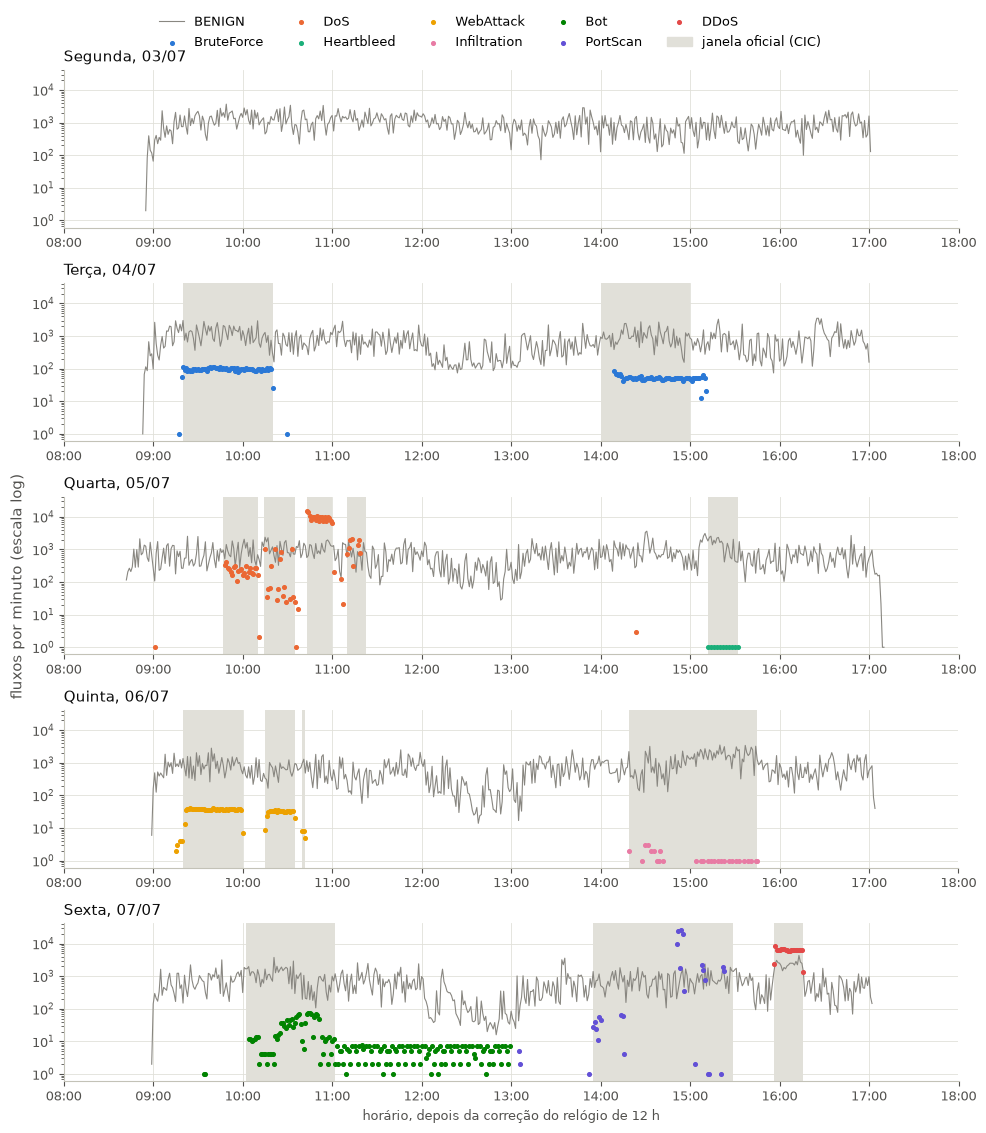

In [3]:
# Agenda publicada em https://www.unb.ca/cic/datasets/ids-2017.html (consultada em 28/10/2026).
# Ataques com várias sub-janelas (Infiltration, PortScan): primeiro início e último fim.
AGENDA = pd.DataFrame(
    [
        ("FTP-Patator", "2017-07-04 09:20", "2017-07-04 10:20"),
        ("SSH-Patator", "2017-07-04 14:00", "2017-07-04 15:00"),
        ("DoS slowloris", "2017-07-05 09:47", "2017-07-05 10:10"),
        ("DoS Slowhttptest", "2017-07-05 10:14", "2017-07-05 10:35"),
        ("DoS Hulk", "2017-07-05 10:43", "2017-07-05 11:00"),
        ("DoS GoldenEye", "2017-07-05 11:10", "2017-07-05 11:23"),
        ("Heartbleed", "2017-07-05 15:12", "2017-07-05 15:32"),
        ("Web Attack - Brute Force", "2017-07-06 09:20", "2017-07-06 10:00"),
        ("Web Attack - XSS", "2017-07-06 10:15", "2017-07-06 10:35"),
        ("Web Attack - Sql Injection", "2017-07-06 10:40", "2017-07-06 10:42"),
        ("Infiltration", "2017-07-06 14:19", "2017-07-06 15:45"),
        ("Bot", "2017-07-07 10:02", "2017-07-07 11:02"),
        ("PortScan", "2017-07-07 13:55", "2017-07-07 15:29"),
        ("DDoS", "2017-07-07 15:56", "2017-07-07 16:16"),
    ],
    columns=["label", "start", "end"],
)
AGENDA[["start", "end"]] = AGENDA[["start", "end"]].apply(pd.to_datetime)

per_minute = (
    df.assign(minute=df[schema.TIMESTAMP].dt.floor("min"))
    .groupby([schema.DAY, schema.FAMILY, "minute"], observed=True)
    .size()
    .rename("flows")
    .reset_index()
)

fig, axes = plt.subplots(len(schema.DAYS), 1, figsize=(10, 11), sharey=True)
for ax, day in zip(axes, schema.DAYS, strict=True):
    date = pd.Timestamp(schema.DAY_DATES[day])
    for row in AGENDA[AGENDA["start"].dt.normalize() == date].itertuples():
        ax.axvspan(row.start, row.end, color=GRID, lw=0)
    data = per_minute[per_minute[schema.DAY] == day]
    for family in schema.FAMILIES:
        part = data[data[schema.FAMILY] == family]
        if part.empty:
            continue
        if family == BENIGN:
            ax.plot(part["minute"], part["flows"], color=COLORS[family], lw=0.8, label=family)
        else:
            ax.scatter(
                part["minute"], part["flows"], s=7, color=COLORS[family], label=family, zorder=3
            )
    ax.set_yscale("log")
    ax.set_xlim(date + pd.Timedelta(hours=8), date + pd.Timedelta(hours=18))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_title(f"{DAY_NAMES[day]}, {date:%d/%m}", loc="left", color=INK)

handles = {}
for ax in axes:
    for handle, label in zip(*ax.get_legend_handles_labels(), strict=True):
        handles.setdefault(label, handle)
handles["janela oficial (CIC)"] = Patch(color=GRID)
fig.legend(
    list(handles.values()), list(handles), loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.03)
)
fig.supylabel("fluxos por minuto (escala log)", color=MUTED)
axes[-1].set_xlabel("horário, depois da correção do relógio de 12 h")
fig.tight_layout()
save(fig, "linha_do_tempo")
plt.show()

In [4]:
tolerance = pd.Timedelta(minutes=5)
rows = []
for row in AGENDA.itertuples():
    ts = df.loc[df[schema.LABEL] == row.label, schema.TIMESTAMP]
    outside = (ts < row.start - tolerance) | (ts > row.end + tolerance)
    rows.append(
        {
            "rótulo": row.label,
            "janela oficial": f"{row.start:%H:%M}–{row.end:%H:%M}",
            "observado": f"{ts.min():%H:%M}–{ts.max():%H:%M}",
            "fluxos": len(ts),
            "fora da janela (±5 min)": int(outside.sum()),
            "% fora": round(100 * outside.mean(), 1),
        }
    )
windows = pd.DataFrame(rows)
display(windows)

,rótulo,janela oficial,observado,fluxos,fora da janela (±5 min),% fora
0,FTP-Patator,09:20–10:20,09:17–10:30,5931,1,0.0
1,SSH-Patator,14:00–15:00,14:09–15:11,3219,254,7.9
2,DoS slowloris,09:47–10:10,09:01–14:24,5372,4,0.1
3,DoS Slowhttptest,10:14–10:35,10:15–10:37,5228,0,0.0
4,DoS Hulk,10:43–11:00,10:43–11:07,172697,141,0.1
5,DoS GoldenEye,11:10–11:23,11:10–11:19,10282,0,0.0
6,Heartbleed,15:12–15:32,15:12–15:32,11,0,0.0
7,Web Attack - Brute Force,09:20–10:00,09:15–10:00,1470,0,0.0
8,Web Attack - XSS,10:15–10:35,10:15–10:35,652,0,0.0
9,Web Attack - Sql Injection,10:40–10:42,10:40–10:42,21,0,0.0


**Leitura.** A correção do relógio está confirmada: os ataques da tarde (SSH-Patator, Heartbleed,
Infiltration, PortScan e DDoS) caem nas janelas oficiais, e sem a correção estariam registrados
entre 1h e 5h da madrugada. Heartbleed, Infiltration, XSS, SQL Injection e DDoS batem com a agenda
ao minuto.

Há duas exceções que merecem registro:

- **Bot**: cerca de um quarto dos fluxos rotulados (24 %) está fora da janela oficial
  (10:02–11:02), com fluxos até 12:59. Pode ser tráfego do botnet que continuou depois da janela,
  como a comunicação com o servidor de comando, ou erro de rotulagem. Só com os fluxos não dá para
  decidir.
- **SSH-Patator**: a janela observada está deslocada cerca de 10 minutos em relação à oficial, e 8 %
  dos fluxos ficam fora dela.

Nos demais, os fluxos fora da janela não passam de 0,1 % de cada rótulo (por exemplo, um fluxo de
DoS slowloris às 9:01 e três às 14h). **Proposta (ADR 0001):** manter os rótulos originais e
registrar essas divergências como limitação, junto com os erros de rotulagem já documentados por
Engelen et al. (2021).

## 3. Atributos redundantes

O CICFlowMeter gera vários atributos que são cópias de outros. Abaixo, todos os pares de atributos
iguais em pelo menos 99,99 % das linhas.

In [5]:
values = {c: df[c].to_numpy() for c in F}
rows = []
for i, a in enumerate(F):
    for b in F[i + 1 :]:
        equal = values[a] == values[b]
        if equal.mean() >= 0.9999:
            rows.append(
                {
                    "atributo": a,
                    "igual a": b,
                    "% linhas iguais": round(100 * equal.mean(), 4),
                    "linhas diferentes": int((~equal).sum()),
                }
            )
display(pd.DataFrame(rows))

std = df["packet_length_std"].astype("float64")
var = df["packet_length_variance"].astype("float64")
same = np.isclose(std**2, var, rtol=1e-3)
print(f"packet_length_variance = packet_length_std² em {100 * same.mean():.2f}% das linhas")

,atributo,igual a,% linhas iguais,linhas diferentes
0,total_fwd_packets,subflow_fwd_packets,100.0000,0
1,total_backward_packets,subflow_bwd_packets,100.0000,0
2,total_length_of_fwd_packets,subflow_fwd_bytes,100.0000,1
3,total_length_of_bwd_packets,subflow_bwd_bytes,99.9942,146
4,fwd_packet_length_mean,avg_fwd_segment_size,100.0000,0
5,bwd_packet_length_mean,avg_bwd_segment_size,100.0000,0
6,fwd_psh_flags,syn_flag_count,100.0000,0
7,fwd_urg_flags,cwe_flag_count,100.0000,0
8,rst_flag_count,ece_flag_count,99.9999,3


packet_length_variance = packet_length_std² em 99.55% das linhas


Uma armadilha apareceu no caminho, na correlação entre `fwd_header_length` e `bwd_header_length`.
A tabela mostra a correlação de Pearson calculada de três jeitos e a de Spearman, que usa só a
ordem dos valores.

In [6]:
a, b = df["fwd_header_length"], df["bwd_header_length"]
rows = df.sample(300_000, random_state=0).index
valid = (a >= 0) & (b >= 0)
display(
    pd.DataFrame(
        {
            "Pearson, amostra de 300 mil": [a.loc[rows].corr(b.loc[rows])],
            "Pearson, conjunto inteiro": [a.corr(b)],
            "Pearson, sem os negativos": [a[valid].corr(b[valid])],
            "Spearman, conjunto inteiro": [a.rank().corr(b.rank())],  # Pearson sobre as posições
            "% linhas iguais": [100 * (a == b).mean()],
        },
        index=["fwd_header_length × bwd_header_length"],
    ).round(4)
)
in_sample = (~valid.loc[rows]).sum()
print(
    f"linhas com tamanho de cabeçalho negativo: {(~valid).sum()} no total, {in_sample} na amostra"
)

,"Pearson, amostra de 300 mil","Pearson, conjunto inteiro","Pearson, sem os negativos","Spearman, conjunto inteiro",% linhas iguais
fwd_header_length × bwd_header_length,1.0,0.0692,0.9988,0.7124,34.659


linhas com tamanho de cabeçalho negativo: 35 no total, 2 na amostra


**Leitura.** São seis pares de colunas idênticas e três quase idênticas. Além delas, a variância é o
quadrado do desvio-padrão em 99,55 % das linhas. Dois pares chamam atenção porque os nomes não têm
nada a ver um com o outro: `fwd_psh_flags` é idêntica a `syn_flag_count`, e `fwd_urg_flags` a
`cwe_flag_count`. É um sinal de defeito do CICFlowMeter na contagem de *flags*, e não de uma relação
real no tráfego.

Na correlação, a de Pearson vai de 1,0 a 0,07 conforme as linhas usadas. Quem decide são algumas
dezenas de valores absurdos de tamanho de cabeçalho (até −32 bilhões, resultado de *overflow* de
inteiro, ver seção 4). Na amostra entram só 2 dessas linhas, e elas bastam para levar a correlação a
1. No conjunto inteiro, a coluna de ida tem 35 desses valores e a de volta, 22: os extremos só
coincidem em parte e derrubam a correlação para 0,07. Sem eles, os fluxos muito grandes dominam e ela volta
para perto de 1. A de Spearman fica em 0,71, que é a relação real: as colunas andam juntas, mas não
são cópias. Por isso a busca por redundâncias usa igualdade direta, e não correlação de Pearson.

**Proposta (ADR 0005):** remover dez atributos, ficando com 60: `subflow_fwd_packets`,
`subflow_bwd_packets`, `subflow_fwd_bytes`, `subflow_bwd_bytes`, `avg_fwd_segment_size`,
`avg_bwd_segment_size`, `syn_flag_count`, `cwe_flag_count`, `ece_flag_count` e
`packet_length_variance`. Para árvores, cópias não mudam o desempenho, mas dividem a importância
entre colunas iguais (o que confunde a explicação com SHAP), aumentam o custo de treino e alongam a
entrada da API.

## 4. Valores negativos e fluxos de duração zero

Atributos de tempo e tamanho não podem ser negativos. A janela TCP inicial, que usa `-1` para "não
observada", fica de fora e é tratada na seção 5.

In [7]:
skip = {"init_win_bytes_forward", "init_win_bytes_backward"}
rows = []
for c in F:
    negative = df.loc[df[c] < 0, c]
    if len(negative) and c not in skip:
        rows.append(
            {
                "atributo": c,
                "linhas": len(negative),
                "mínimo": negative.min(),
                "mediana": negative.median(),
                "máximo": negative.max(),
            }
        )
display(pd.DataFrame(rows))

,atributo,linhas,mínimo,mediana,máximo
0,flow_duration,107,-1.300000e+01,-1.0,-1.000000e+00
1,flow_bytes_s,78,-2.610000e+08,-12000000.0,-4.615385e+05
2,flow_packets_s,107,-2.000000e+06,-2000000.0,-1.538462e+05
3,flow_iat_mean,107,-1.300000e+01,-1.0,-1.000000e+00
4,flow_iat_max,107,-1.300000e+01,-1.0,-1.000000e+00
5,flow_iat_min,2880,-1.400000e+01,-1.0,-1.000000e+00
6,fwd_iat_min,17,-1.200000e+01,-1.0,-1.000000e+00
7,fwd_header_length,35,-3.221223e+10,-167770496.0,-1.100000e+01
8,bwd_header_length,22,-1.073741e+09,-83885184.0,-8.388501e+07
9,min_seg_size_forward,35,-5.368707e+08,-83885312.0,-1.000000e+00


In [8]:
time_cols = ["flow_iat_min", "fwd_iat_min"]
size_cols = ["fwd_header_length", "bwd_header_length", "min_seg_size_forward"]
groups = {
    "tempo entre pacotes negativo": (df[time_cols] < 0).any(axis=1) & (df["flow_duration"] >= 0),
    "duração negativa": df["flow_duration"] < 0,
    "cabeçalho negativo (overflow)": (df[size_cols] < 0).any(axis=1),
}
by_label = pd.DataFrame(
    {name: df.loc[mask, schema.LABEL].value_counts() for name, mask in groups.items()}
)
display(by_label[by_label.sum(axis=1) > 0])

,tempo entre pacotes negativo,duração negativa,cabeçalho negativo (overflow)
label,,,
BENIGN,2580,107,35
FTP-Patator,4,0,0
SSH-Patator,2,0,0
DoS Hulk,158,0,0
DoS GoldenEye,5,0,0
Heartbleed,4,0,0
Infiltration,1,0,0
DDoS,19,0,0


Os fluxos de duração zero já foram removidos pela limpeza (regra R5), porque suas taxas por segundo
são infinitas ou indefinidas. Para ver quem eles eram, é preciso voltar aos arquivos originais:

In [9]:
parts = []
for path in sorted((ROOT / "data" / "raw").glob("*.csv")):
    raw = pd.read_csv(path, usecols=[7, 84], encoding="latin-1", low_memory=False)
    raw.columns = ["flow_duration", "label"]
    parts.append(raw.dropna(subset=["label"]))
raw = pd.concat(parts, ignore_index=True)
canonical = {s: schema.LABELS[schema.normalize_label(s)][0] for s in raw["label"].unique()}
raw["label"] = raw["label"].map(canonical)

zero = raw["flow_duration"] == 0
zero_table = pd.DataFrame(
    {"duração zero": raw.loc[zero, "label"].value_counts(), "total": raw["label"].value_counts()}
)
zero_table = zero_table[zero_table["duração zero"] > 0].astype(int)
zero_table["%"] = (100 * zero_table["duração zero"] / zero_table["total"]).round(2)
display(zero_table.sort_values("duração zero", ascending=False))

,duração zero,total,%
label,,,
BENIGN,1777,2273097,0.08
DoS Hulk,949,231073,0.41
PortScan,126,158930,0.08
Bot,10,1966,0.51
FTP-Patator,3,7938,0.04
DDoS,2,128027,0.00


**Leitura.** Há três tipos de problema, com causas diferentes:

- **Tempos levemente negativos** (de −14 a −1 µs, quase todos em `flow_iat_min`): parecem
  imprecisão de relógio na captura. Afetam 2.773 fluxos, entre eles 4 dos 11 de Heartbleed e 1 dos
  36 de Infiltration. Remover essas linhas custaria caro justamente às classes raras.
- **Duração negativa** (107 fluxos, todos normais): as taxas calculadas a partir dela saem com
  valores absurdos, como −2 milhões de pacotes por segundo.
- **Tamanhos de cabeçalho negativos** (35 fluxos, todos normais): valores de até −32 bilhões, que só
  podem ser *overflow* de inteiro.

E os 2.867 fluxos de **duração zero** (0,1 % do total) foram descartados na limpeza, sendo 949 de
DoS Hulk e 126 de PortScan. Fluxos instantâneos existem em tráfego real, e a própria
`flow_duration = 0` já sinaliza o caso para o modelo. Descartá-los também faria a API rejeitar esse
tipo de fluxo em produção.

**Proposta (ADR 0006):**

1. tempos negativos viram 0;
2. fluxos com duração zero (incluindo os que ficam com duração zero pela regra 1) voltam ao conjunto,
   com as taxas por segundo iguais a 0;
3. as 35 linhas com tamanho de cabeçalho negativo são removidas.

## 5. Janela TCP `-1` e protocolo

In [10]:
protocol = df["protocol"].map({0: "0 (outros)", 6: "6 (TCP)", 17: "17 (UDP)"})
window = (df["init_win_bytes_forward"] == -1).map({False: "janela observada", True: "janela = -1"})
display(pd.crosstab(protocol, window))
display((100 * pd.crosstab(df[schema.FAMILY], protocol, normalize="index")).round(1))

init_win_bytes_forward,janela = -1,janela observada
protocol,,
0 (outros),1565,0
17 (UDP),891384,0
6 (TCP),0,1603593


protocol,0 (outros),17 (UDP),6 (TCP)
family,,,
BENIGN,0.1,43.0,56.9
BruteForce,0.0,0.0,100.0
DoS,0.0,0.0,100.0
Heartbleed,0.0,0.0,100.0
WebAttack,0.0,0.0,100.0
Infiltration,0.0,0.0,100.0
Bot,0.0,0.0,100.0
PortScan,0.0,0.0,100.0
DDoS,0.0,0.0,100.0


**Leitura.** A janela de ida igual a `-1` é exatamente o mesmo que "não é TCP": nenhum fluxo TCP tem
`-1`, e todos os fluxos UDP e de outros protocolos têm. Ela não é ruído: é informação sobre o
protocolo.

O ponto mais importante é outro: **100 % dos ataques são TCP**, enquanto 43 % do tráfego normal é
UDP. Neste conjunto, "UDP" significa "normal" sem exceção, e um modelo vai aprender esse atalho. Ele
não vale fora daqui, porque existem ataques por UDP (inundações, amplificação de DNS). Não há o que
remover, já que o problema está na composição do conjunto e não em uma coluna. **Proposta:**
registrar como limitação no relatório e no README. Para os modelos de anomalia, que aplicam
logaritmo, o `-1` será trocado por 0, já que o protocolo carrega a mesma informação.

## 6. Porta de destino

Quanto a porta de destino, sozinha, já separa as famílias? Para medir, um "classificador" mínimo:
cada porta recebe a família mais comum dela no treino do protocolo P1, e portas nunca vistas são
classificadas como tráfego normal.

In [11]:
top_ports = (
    df[df[schema.FAMILY] != BENIGN]
    .groupby(schema.FAMILY, observed=True)["destination_port"]
    .agg(
        lambda s: ", ".join(
            f"{int(port)} ({100 * share:.0f}%)"
            for port, share in s.value_counts(normalize=True).head(3).items()
        )
    )
)
display(top_ports.to_frame("portas mais comuns"))

,portas mais comuns
family,
BruteForce,"21 (65%), 22 (35%), 80 (0%)"
DoS,80 (100%)
Heartbleed,444 (100%)
WebAttack,80 (100%)
Infiltration,444 (100%)
Bot,"8080 (64%), 1841 (0%), 1845 (0%)"
PortScan,"80 (0%), 22 (0%), 21 (0%)"
DDoS,"80 (100%), 64869 (0%), 64873 (0%)"


In [12]:
split = ROOT / "data" / "processed" / "temporal"
train = pd.read_parquet(split / "train.parquet", columns=["destination_port", schema.FAMILY])
test = pd.read_parquet(split / "test.parquet", columns=["destination_port", schema.FAMILY])

counts = (
    train.groupby(["destination_port", schema.FAMILY], observed=True).size().reset_index(name="n")
)
port_to_family = (
    counts.sort_values("n")
    .drop_duplicates("destination_port", keep="last")
    .set_index("destination_port")[schema.FAMILY]
    .astype(str)
)
predicted = test["destination_port"].map(port_to_family).fillna(BENIGN)
actual = test[schema.FAMILY].astype(str)

rows = []
for family in schema.FAMILIES:
    hits = ((predicted == family) & (actual == family)).sum()
    precision = hits / max((predicted == family).sum(), 1)
    recall = hits / max((actual == family).sum(), 1)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append(
        {
            "família": family,
            "fluxos no teste": int((actual == family).sum()),
            "precisão": precision,
            "revocação": recall,
            "F1": f1,
        }
    )
port_only = pd.DataFrame(rows).round(3)
display(port_only)
print(f"macro-F1 só com a porta: {port_only['F1'].mean():.3f}")

,família,fluxos no teste,precisão,revocação,F1
0,BENIGN,414307,0.860,0.975,0.914
1,BruteForce,1830,0.634,0.648,0.641
2,DoS,38715,0.000,0.000,0.000
3,Heartbleed,2,0.000,0.000,0.000
4,WebAttack,428,0.000,0.000,0.000
5,Infiltration,7,0.000,0.000,0.000
6,Bot,390,0.441,1.000,0.612
7,PortScan,18026,0.655,0.965,0.780
8,DDoS,25602,0.000,0.000,0.000


macro-F1 só com a porta: 0.327


**Leitura.** Só com a porta, a macro-F1 já é de cerca de 0,33, e algumas famílias são quase
totalmente reconhecidas: 96 % do PortScan (a varredura toca milhares de portas incomuns, que no
treino só aparecem nela) e 100 % do Bot (a maior parte dos fluxos dele vai para a porta 8080 do
servidor de comando). Heartbleed e
Infiltration usam a mesma porta, 444, escolhida pelo atacante do laboratório. Já DoS, DDoS e ataques
web usam a porta 80, como o tráfego normal, e a porta não ajuda.

Em parte isso é informação legítima, já que a força bruta em FTP e SSH mira as portas 21 e 22 em
qualquer rede. Mas muito do resultado é atalho do laboratório, que não se transfere para outras
redes. **Proposta (ADR 0004):** treinar sem a porta por padrão e rodar o experimento com a porta,
para medir quanto ela contribui.

## 7. Distribuições e o limite de 120 s

In [13]:
cols = [
    "flow_duration",
    "flow_bytes_s",
    "total_length_of_fwd_packets",
    "flow_iat_mean",
    "fwd_packets_s",
]
quantiles = df[cols].quantile([0.5, 0.9, 0.99, 1.0]).T
quantiles.columns = ["mediana", "p90", "p99", "máximo"]
display(quantiles)

capped = df["flow_duration"] >= 119.9e6
longest = df["flow_duration"].max() / 1e6
print(f"flow_duration máximo: {longest:.0f} s; {fmt(capped.sum())} fluxos no limite")
display(
    df.loc[capped, schema.FAMILY].value_counts().loc[lambda s: s > 0].to_frame("fluxos no limite")
)

,mediana,p90,p99,máximo
flow_duration,52028.500000,8.611013e+07,1.179228e+08,1.200000e+08
flow_bytes_s,3610.609375,1.232759e+06,1.233333e+07,2.071000e+09
total_length_of_fwd_packets,66.000000,1.005000e+03,1.160700e+04,1.290000e+07
flow_iat_mean,20704.333984,4.525525e+06,2.210000e+07,1.200000e+08
fwd_packets_s,36.138700,2.439024e+04,7.500000e+05,3.000000e+06


flow_duration máximo: 120 s; 1.932 fluxos no limite


,fluxos no limite
family,
BENIGN,1925
Infiltration,6
DoS,1


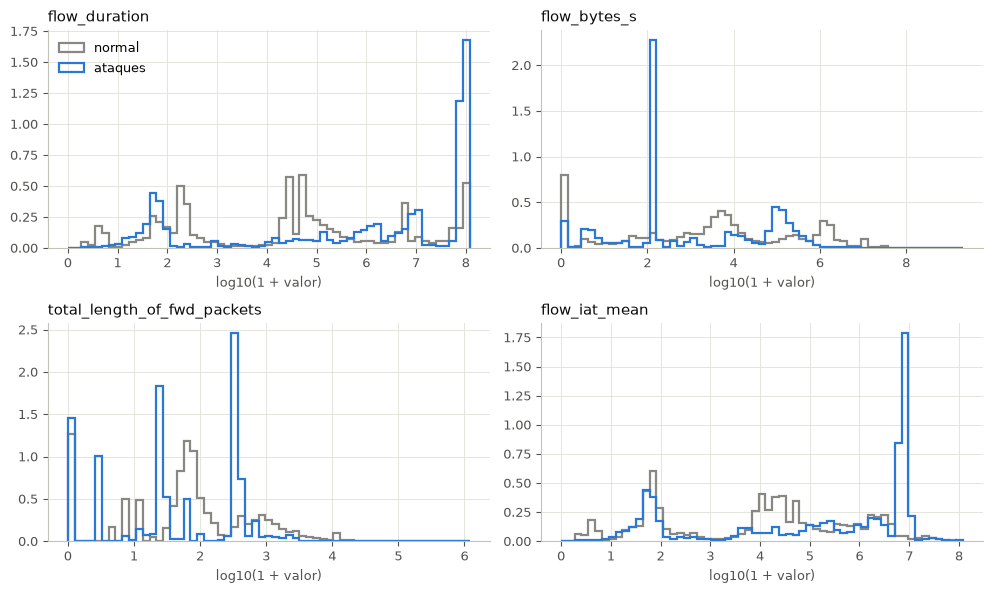

In [14]:
sample = df.sample(400_000, random_state=0)
is_attack = sample[schema.FAMILY] != BENIGN
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, col in zip(axes.flat, cols[:4], strict=True):
    x = np.log10(1 + sample[col].clip(lower=0))
    bins = np.linspace(0, x.max(), 60)
    style = {"bins": bins, "density": True, "histtype": "step", "lw": 1.6}
    ax.hist(x[~is_attack], color=COLORS[BENIGN], label="normal", **style)
    ax.hist(x[is_attack], color=PALETTE[0], label="ataques", **style)
    ax.set_title(col, loc="left", color=INK)
    ax.set_xlabel("log10(1 + valor)")
axes[0, 0].legend()
fig.tight_layout()
save(fig, "distribuicoes")
plt.show()

**Leitura.** As distribuições têm caudas muito longas: em `flow_bytes_s`, o máximo é centenas de
milhares de vezes a mediana. A duração é medida em microssegundos e nunca passa de 120 s, o tempo
limite de fluxo do CICFlowMeter: conexões mais longas são cortadas em vários fluxos. Seis dos 36
fluxos de Infiltration batem nesse limite, o que faz sentido para conexões longas de um invasor já
instalado.

Para as árvores (etapa 2), as caudas não importam, porque os cortes dependem só da ordem dos
valores. Para o Isolation Forest e o autoencoder (etapa 3), a proposta é aplicar `log1p` antes da
padronização, já previsto na arquitetura.

## 8. O tráfego normal muda entre os dias?

No protocolo P2, o detector de anomalias aprende o tráfego normal de segunda a quarta e é testado
em quinta e sexta. Se o normal mudar entre os dias, a taxa de falsos positivos no teste será maior
que a medida na validação. Para medir a mudança atributo a atributo, uso o PSI (*population
stability index*) de cada dia em relação à segunda-feira, com faixas definidas pelos decis da
segunda. Pela convenção usual, PSI abaixo de 0,1 indica mudança pequena, e acima de 0,25, mudança
relevante.

In [15]:
def psi(reference, current, bins=10):
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return np.nan
    inner = edges[1:-1]
    size = len(edges) - 1
    ref = np.bincount(np.searchsorted(inner, reference, side="right"), minlength=size)
    cur = np.bincount(np.searchsorted(inner, current, side="right"), minlength=size)
    ref = np.clip(ref / len(reference), 1e-6, None)
    cur = np.clip(cur / len(current), 1e-6, None)
    return float(np.sum((cur - ref) * np.log(cur / ref)))


benign = df[df[schema.FAMILY] == BENIGN]
by_day = {day: benign[benign[schema.DAY] == day] for day in schema.DAYS}
drift = pd.DataFrame(
    {
        DAY_NAMES[day]: {
            c: psi(by_day["monday"][c].to_numpy(), by_day[day][c].to_numpy()) for c in F
        }
        for day in schema.DAYS[1:]
    }
).dropna()
print(
    f"{len(drift)} atributos avaliados (os demais têm poucos valores distintos para formar faixas)"
)
display(pd.DataFrame({"PSI > 0,10": (drift > 0.10).sum(), "PSI > 0,25": (drift > 0.25).sum()}).T)

58 atributos avaliados (os demais têm poucos valores distintos para formar faixas)


,Terça,Quarta,Quinta,Sexta
"PSI > 0,10",12,0,0,0
"PSI > 0,25",4,0,0,0


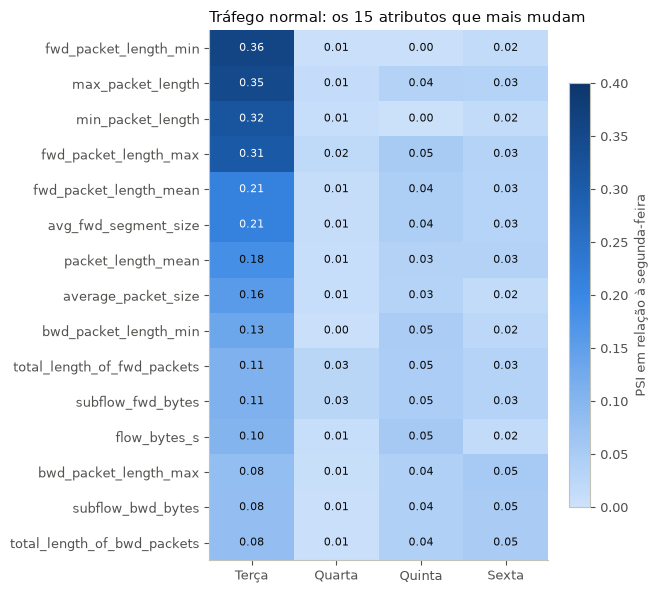

In [16]:
top = drift.loc[drift.max(axis=1).sort_values(ascending=False).index[:15]]
blues = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
fig, ax = plt.subplots(figsize=(6.5, 6))
image = ax.imshow(top.to_numpy(), cmap=blues, vmin=0, vmax=0.4, aspect="auto")
ax.set_xticks(range(top.shape[1]), top.columns)
ax.set_yticks(range(top.shape[0]), top.index)
ax.grid(False)
for (i, j), value in np.ndenumerate(top.to_numpy()):
    ax.text(
        j,
        i,
        f"{value:.2f}",
        ha="center",
        va="center",
        fontsize=8,
        color="white" if value > 0.2 else INK,
    )
fig.colorbar(image, ax=ax, label="PSI em relação à segunda-feira", shrink=0.8)
ax.set_title("Tráfego normal: os 15 atributos que mais mudam", loc="left", color=INK)
fig.tight_layout()
save(fig, "deriva_normal")
plt.show()

**Leitura.** De quarta a sexta, nenhum atributo do tráfego normal muda de forma relevante em relação
à segunda. A terça é a exceção: os atributos de tamanho de pacote mudam, o que sugere uma mistura
de serviços diferente nesse dia. Para o P2, a notícia é boa, porque o normal de quinta e sexta
(teste) se parece com o de segunda (treino).

O PSI olha um atributo de cada vez e não capta mudanças na combinação entre eles. Por isso, a
proposta é não tomar nenhuma ação agora e medir a taxa de falsos positivos no teste do P2,
comparando com a da validação.

## 9. Classes raras nos protocolos de divisão

In [17]:
splits = json.loads((ROOT / "reports" / "splits.json").read_text(encoding="utf-8"))
names = {"random": "P0", "temporal": "P1", "unseen": "P2"}
rare = pd.DataFrame(
    {
        f"{names[protocol]} {part}": {f: counts.get(f, 0) for f in ["Heartbleed", "Infiltration"]}
        for protocol, parts in splits.items()
        for part, counts in parts.items()
    }
)
display(rare)

,P0 train,P0 val,P0 test,P1 train,P1 val,P1 test,P2 train,P2 val,P2 test
Heartbleed,7,2,2,7,2,2,9,2,0
Infiltration,22,7,7,22,7,7,0,0,36


**Leitura.** No P0 e no P1, o teste tem 2 fluxos de Heartbleed e 7 de Infiltration: qualquer métrica
por classe com esses números é ruído (um acerto a mais muda a revocação em 50 pontos). No P2,
Heartbleed só aparece no treino e na validação, e Infiltration só no teste.

**Proposta (ADR 0003):** manter as duas classes no conjunto, mas fora do treino e da avaliação
multiclasse do P0 e do P1, e reportá-las só nas avaliações binárias (ataque ou normal), sempre com o
número de amostras ao lado.

## 10. Resumo: decisões propostas

| # | Tema | Achado | Proposta | ADR |
|---|---|---|---|---|
| 1 | Versão do conjunto | A agenda oficial confirma a correção do relógio. Bot e SSH-Patator divergem da agenda | Manter a versão original e os rótulos; registrar as divergências como limitação | 0001 |
| 2 | Protocolos de divisão | P0, P1 e P2 funcionam como planejado | Manter os três, sem mudanças | 0002 |
| 3 | Classes raras | Heartbleed (11) e Infiltration (36) têm de 2 a 7 fluxos no teste do P0/P1 | Fora do multiclasse; só avaliação binária, com o número de amostras | 0003 |
| 4 | Porta de destino | Só a porta dá macro-F1 de 0,33; 96 % do PortScan e 100 % do Bot | Excluir por padrão; experimento com a porta | 0004 |
| 5 | Atributos redundantes | 9 pares de cópias e a variância | Remover 10 atributos (70 → 60) | 0005 |
| 6 | Negativos e duração zero | Tempos de −1 a −14 µs; *overflow* em cabeçalhos; 2.867 fluxos instantâneos descartados | Tempos → 0; manter fluxos instantâneos com taxas 0; remover 35 linhas com *overflow* | 0006 |
| 7 | Janela `-1` e protocolo | `-1` é exatamente "não TCP"; 100 % dos ataques são TCP | Manter; registrar o atalho "UDP = normal" como limitação | — |
| 8 | Caudas pesadas | Máximo até centenas de milhares de vezes a mediana; duração limitada a 120 s | `log1p` e padronização só para os modelos de anomalia | — |
| 9 | Mudança do normal | Só a terça destoa (tamanhos de pacote) | Nenhuma ação; medir a FPR no teste do P2 | — |

As propostas 5 e 6 mudam o pipeline de limpeza e serão implementadas, com testes, depois de
aprovadas.